# **Start Section:**

In [1]:
# FIX K1: same notebook runs on Google Colab (Drive) or Kaggle (internet on).
# On Kaggle the working dir is /kaggle/working, so the original "./drive/MyDrive/..." paths
# below are reused unchanged; the dataset is copied there as train.csv / test.csv.
import os, glob, shutil
IN_KAGGLE = os.path.exists("/kaggle/working")
if IN_KAGGLE:
    _data_dir = "./drive/MyDrive/Regression/noise_uncertainty_analysis/data"
    os.makedirs(_data_dir, exist_ok=True)
    shutil.copy(glob.glob("/kaggle/input/**/d06_a.csv", recursive=True)[0], f"{_data_dir}/train.csv")  # noise train
    shutil.copy(glob.glob("/kaggle/input/**/d06_b.csv", recursive=True)[0], f"{_data_dir}/test.csv")   # noise test
    print("Kaggle: noise data copied to", _data_dir)
else:
    from google.colab import drive
    drive.mount('/content/drive')


Kaggle: noise data copied to ./drive/MyDrive/Regression/noise_uncertainty_analysis/data


In [2]:
# FIX K1: original Colab install block kept as-is (runs only on Colab).
# On Kaggle: install only the packages the Kaggle image lacks, pinned to the Colab versions,
# and do NOT restart the kernel.
if IN_KAGGLE:
    !pip install -q optuna==4.6.0 optunahub==0.4.0 cmaes==0.12.0 xgboost==3.1.2 catboost==1.2.8 gpboost==1.6.1 ngboost==0.5.8 pgbm==2.2.0 pytorch-tabnet2==4.5.3 interpret==0.7.4 lime==0.2.0.1 bayesian-optimization==3.2.0 properscoring==0.1 XlsxWriter==3.2.9 mapie==0.6.0 puncc==0.8.0
else:
    import os
    os.environ["PIP_CONSTRAINT"] = "/tmp/numpy_constraint.txt"
    !echo "numpy==1.26.4" > /tmp/numpy_constraint.txt

    !pip uninstall -y torch torchaudio torchvision \
        torchao torchcodec torchdata torchtune torchsummary -q 2>/dev/null

    !pip uninstall -y tensorflow tensorflow-text tensorflow-hub tf-keras \
        tensorflow_decision_forests tensorflow-probability \
        tensorflow-Datasets tensorflow-metadata -q 2>/dev/null

    !pip uninstall -y numpy scikit-learn shap xgboost lightgbm dask \
        seaborn plotly openpyxl Cython catboost interpret lime -q 2>/dev/null

    !pip install numpy==1.26.4 -q
    !pip install scikit-learn==1.6.1 -q
    !pip install torch==2.9.0 -q

    !pip install lightgbm==4.6.0 -q
    !pip install xgboost==3.1.2 -q
    !pip install catboost==1.2.8 -q
    !pip install gpboost==1.6.1 -q
    !pip install ngboost==0.5.8 -q
    !pip install pgbm==2.2.0 -q
    !pip install pytorch-tabnet2==4.5.3 -q

    !pip install bayesian-optimization==3.2.0 -q
    !pip install optuna==4.6.0 -q
    !pip install optunahub==0.4.0 -q
    !pip install cmaes==0.12.0 -q

    !pip install shap==0.44.0 -q
    !pip install lime==0.2.0.1 -q
    !pip install interpret==0.7.4 -q

    !pip install mapie==0.6.0 -q
    !pip install puncc==0.8.0 -q
    !pip install skorch==1.3.1 -q
    !pip install properscoring==0.1 -q

    !pip install dask[dataframe]==2025.12.0 -q
    !pip install cython==3.0.12 -q
    !pip install seaborn==0.13.2 -q
    !pip install plotly==5.24.1 -q
    !pip install kaleido==1.2.0 -q
    !pip install openpyxl==3.1.5 -q
    !pip install XlsxWriter==3.2.9 -q
    !pip install cp==2020.12.3 -q

    !pip install numpy==1.26.4 --force-reinstall --no-deps -q

    os._exit(0)


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


# **Imports**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.svm import SVR
import ngboost
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from gpboost import GPBoostRegressor
from ngboost import NGBRegressor
import optuna
import optunahub
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from interpret import show
from interpret.blackbox import LimeTabular, ShapKernel
from optuna.samplers import RandomSampler
import random
import time
from ngboost.distns import Normal
from ngboost.scores import LogScore
from scipy.stats import norm
from optuna.samplers import BaseSampler
from optuna.samplers import GridSampler
from optuna.samplers import TPESampler
from optuna.samplers import PartialFixedSampler
from optuna.samplers import CmaEsSampler
from optuna.samplers import QMCSampler
from optuna.samplers import NSGAIIISampler
from optuna.samplers import NSGAIISampler
from optuna.samplers import BruteForceSampler
from optuna.samplers import GPSampler
from interpret import set_visualize_provider
from interpret.provider import InlineProvider
from interpret.glassbox import ExplainableBoostingRegressor
from interpret import show
import plotly.express as px
from io import BytesIO
from openpyxl import Workbook, load_workbook
import os
import properscoring as ps
import io
from openpyxl.drawing.image import Image as openpyxlImage
import warnings
import xlsxwriter
from openpyxl.drawing.image import Image
from pgbm.sklearn import HistGradientBoostingRegressor
import torch
from pgbm.torch import PGBM
import plotly.graph_objects as go
warnings.filterwarnings('ignore')
import pickle
import json
from mapie.subsample import Subsample
from sklearn.model_selection import PredefinedSplit  # FIX M3


def _split_cv(n, seed, calib_fraction=0.5):
    """FIX B9: one fit / calibration split (split conformal) written as a PredefinedSplit, because
    MAPIE 0.6 accepts only BaseCrossValidator objects and rejects ShuffleSplit.
    A seeded random half of the training rows is used for calibration."""
    import numpy as _np
    fold = -_np.ones(n, dtype=int)                      # -1 = used to fit the model
    fold[_np.random.RandomState(seed).permutation(n)[: int(round(calib_fraction * n))]] = 0   # 0 = calibration
    return PredefinedSplit(fold)
from mapie.regression import MapieRegressor
from deel.puncc.metrics import regression_sharpness, regression_mean_coverage
from deel.puncc.api.prediction import BasePredictor, DualPredictor
from deel.puncc.regression import SplitCP, CVPlus, CQR
from deel.puncc.plotting import plot_prediction_intervals
from sklearn.model_selection import train_test_split
from typing_extensions import TypedDict
from typing import Union
from mapie.metrics import regression_coverage_score
from sklearn.model_selection import KFold
from PIL import Image as PImage
from openpyxl.utils.dataframe import dataframe_to_rows
from pytorch_tabnet import TabNetRegressor

[1/2] c++ -MMD -MF splitgain_cpu.o.d -DTORCH_EXTENSION_NAME=split_decision -DTORCH_API_INCLUDE_EXTENSION_H -isystem /usr/local/lib/python3.13/dist-packages/torch/include -isystem /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/api/include -isystem /usr/include/python3.13 -fPIC -std=c++17 -c /usr/local/lib/python3.13/dist-packages/pgbm/torch/splitgain_cpu.cpp -o splitgain_cpu.o 


[2/2] c++ splitgain_cpu.o -shared -L/usr/local/lib/python3.13/dist-packages/torch/lib -lc10 -ltorch_cpu -ltorch -ltorch_python -o split_decision.so


I0000 00:00:1795364946.342473      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795364960.034429      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
# Go to find & replace button and replace (noise_uncertainty_analysis) with your folder name. Rename your train and test Dataset as train.csv and test.csv.
# Modify the names of the feature in the below cell.
# Replace (str) with actual data label name.

In [5]:
feature_names = ['A', 'B', 'C', 'D', 'O']
TARGET_LABEL = 'Noise level (Leq)'  # FIX B12: target name used in plot labels (was 'str', the concrete dataset's target, on every dataset)

In [6]:
train_data_path = "./drive/MyDrive/Regression/noise_uncertainty_analysis/data/train.csv"
test_data_path = "./drive/MyDrive/Regression/noise_uncertainty_analysis/data/test.csv"
train_data = pd.read_csv(train_data_path)
test_data = pd.read_csv(test_data_path)
print("Training data loaded successfully.")
print("Test data loaded successfully.")

Training data loaded successfully.
Test data loaded successfully.


In [7]:
print("\nShape of training data:", train_data.shape)
print("First 5 rows of training data:\n", train_data.head(5))
print("\nShape of test data:", test_data.shape)
print("First 5 rows of test data:\n", test_data.head(5))


Shape of training data: (168, 6)
First 5 rows of training data:
       A    B    C    D   O    Leq
0   894  354  228   30  42  70.06
1  1068  312  234   24  24  69.14
2  1506  894  198  222  18  73.02
3  1188  498  252  354  18  75.71
4  1068  438  210  366  30  70.78

Shape of test data: (60, 6)
First 5 rows of test data:
       A    B    C    D   O    Leq
0  1032  282   90  108   6  70.07
1  1188  498  252  408  18  72.90
2   570   90   60   84  24  68.66
3   450  156  150   72   0  50.24
4   240   66   18   24   0  40.17


In [8]:
X_train = train_data.iloc[:, :-1]
y_train = train_data.iloc[:, -1]
X_test = test_data.iloc[:, :-1]
y_test = test_data.iloc[:, -1]
# FIX D4 / D5 (approved 2026-11-22): settings that follow the test-set size
N_BINS = max(2, min(10, len(y_test) // 10))  # D4: bins for binned metrics (was 10 on every dataset; pile: 2-3 points per bin)
COP_T_BURNIN = min(50, len(y_test) // 2)  # D5: COP burn-in (was 50, so with < 50 test points COP's correction never started)
x_test= X_test
print("\nShape of X_train:", X_train.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_test:", y_test.shape)


Shape of X_train: (168, 5)
Shape of y_train: (168,)
Shape of X_test: (60, 5)
Shape of y_test: (60,)


In [9]:
# Apply z-score normalization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Print the first five rows of the normalized data
print("\nFirst five rows of normalized X_train:")
print(X_train[:5])

print("\nFirst five rows of normalized X_test:")
print(X_test[:5])


First five rows of normalized X_train:
[[-0.34508703 -0.52871218  0.0597039  -1.05667951  1.31930842]
 [-0.08377773 -0.63289541  0.09903824 -1.09452265  0.25541811]
 [ 0.57400083  0.8107865  -0.13696778  0.15430089 -0.09921199]
 [ 0.09643557 -0.17151253  0.21704125  0.98684991 -0.09921199]
 [-0.08377773 -0.32034572 -0.05829911  1.06253618  0.61004822]]

First five rows of normalized X_test:
[[-0.13784172 -0.707312   -0.84498584 -0.56471872 -0.8084722 ]
 [ 0.09643557 -0.17151253  0.21704125  1.32743815 -0.09921199]
 [-0.83166295 -1.1835782  -1.04165752 -0.71609127  0.25541811]
 [-1.01187626 -1.01986169 -0.45164247 -0.79177755 -1.16310231]
 [-1.32724954 -1.24311147 -1.31699788 -1.09452265 -1.16310231]]


# **Functions:**

In [10]:
# Define the model classes
model_classes = {
    'Random Forest': RandomForestRegressor,
    'Gradient Boosting': GradientBoostingRegressor,
    'XGBoost': XGBRegressor,
    'LightGBM': LGBMRegressor,
    'GPBoost': GPBoostRegressor,
    'CatBoost': CatBoostRegressor,
    'HistGradientBoosting': HistGradientBoostingRegressor,
    'TabNet': TabNetRegressor,
    'NGBoost': NGBRegressor
}

def _ensure_excel_file(path):
    import os
    import pandas as pd
    if not os.path.exists(path):
        parent = os.path.dirname(path)
        if parent:
            os.makedirs(parent, exist_ok=True)
        pd.DataFrame().to_excel(path)
    return path

In [11]:
def get_best_model_params(results, model_name):
    # Map model names to dictionary keys, assuming keys are strings like 'XGBoost' and not objects
    model_keys = {
        'LightGBM': 'LightGBM',
        'XGBoost': 'XGBoost',
        'GPBoost': 'GPBoost',
        'NGBoost': 'NGBoost',
        'GradientBoosting': 'Gradient Boosting',
        'HGBR' : 'HistGradientBoosting',
        'CatBoost' : 'CatBoost',
        'TabNet' : 'TabNet',
        'PGBM' : 'PGBM'
    }

    # Ensure the requested model name is valid
    if model_name not in model_keys:
        raise ValueError(f"Model name '{model_name}' is not recognized. Available models are: {list(model_keys.keys())}")

    # Filter out entries for the specified model
    model_entries = {key: value for key, value in results.items() if key[0] == model_keys[model_name]}

    # Find the entry with the best (lowest) 'best_score'
    best_entry_key, best_entry_value = min(model_entries.items(), key=lambda item: item[1]['best_score'])

    # Return the best hyperparameters
    return best_entry_value['best_params']

In [12]:
# FIX M4: one miscoverage level for every method in this notebook (MAPIE and PUNCC).
# Was: MAPIE used 0.05 and PUNCC 0.1, so their coverages/widths could not be compared.
ALPHA = 0.1   # target coverage = 1 - ALPHA = 90%


In [13]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test.to_numpy()[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test.to_numpy()[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.to_numpy().ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE(model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path):
    """
    Train and plot conformal prediction intervals using different strategies and save the plots and
    table of ymin/ymax/y_pred to different worksheets in an Excel file for each strategy.

    Parameters:
    - model_class: The class of the model to be used (e.g., LGBMRegressor).
    - best_params: Dictionary of best parameters for the model.
    - X_train: Training features.
    - y_train: Training target.
    - X_test: Test features.
    - y_test: Test target.
    - model_name: Name of the model for labeling purposes.
    - excel_file_path: Path to the Excel file where the plots will be saved.
    """
    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    # Define miscoverage
    MISCOVERAGE: float = ALPHA  # FIX M4: was 0.05  # MISCOVERAGE = alpha # CONFIDENCE = 1-alpha
    warnings.filterwarnings("ignore")  # to suppress them

    # Create output directory
    os.makedirs('output/regression', exist_ok=True)

    # Define strategies and parameters
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Define base estimators
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    # Train strategies using MAPIE
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred) # Corrected line: Removed y_test
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test.to_numpy() - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the results for the test set
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names) * 3 + 1 + len(_strategies) # Strategy plots + Goodness plots + Width plots + Comparison plot + Coverage vs Width plots
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))

    plot_index = 0 # Keep track of the current plot index

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot for comparison
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet for the plots
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = 'conformal_predictions_MAPIE'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        all_rows = []
        y_true_np = y_test.to_numpy().ravel()  # To save multiple conversions
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()



In [14]:
# FIX M1: Conformalized Quantile Regression (Romano et al. 2019) needs models of the
# alpha/2 and 1-alpha/2 QUANTILES. Was: both "quantile" models were the same mean model, so the
# band was mean +/- a constant (split conformal with extra steps), not CQR.
# QuantileModel fits each base model at quantile level q in the way that model supports:
#   native quantile loss  - LightGBM, GPBoost, XGBoost, sklearn GradientBoosting, CatBoost, TabNet
#   predictive distribution - NGBoost (ppf), PGBM (sampled forecasts), pgbm HistGradientBoosting (mean, std)
from scipy.stats import norm as _norm
from sklearn.base import BaseEstimator, RegressorMixin


class QuantileModel(BaseEstimator, RegressorMixin):
    def __init__(self, model_class, params, q):
        self.model_class = model_class
        self.params = params
        self.q = q

    def _kind(self):
        return self.model_class.__name__

    def fit(self, X, y):
        p, q, name = dict(self.params or {}), self.q, self._kind()
        X_ = np.asarray(X)
        y_ = np.asarray(y).ravel()
        if name in ("LGBMRegressor", "GPBoostRegressor"):
            p.update(objective="quantile", alpha=q)
        elif name == "XGBRegressor":
            p.update(objective="reg:quantileerror", quantile_alpha=q)
        elif name == "GradientBoostingRegressor":
            p.update(loss="quantile", alpha=q)
        elif name == "CatBoostRegressor":
            p.pop("objective", None)
            p.update(loss_function=f"Quantile:alpha={q}")
        if "TabNet" in name:
            import torch as _torch

            def _pinball(y_pred, y_true):
                e = y_true - y_pred
                return _torch.mean(_torch.maximum(q * e, (q - 1) * e))
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_, loss_fn=_pinball)
        else:
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_)
        return self

    def predict(self, X):
        X_, q, name = np.asarray(X), self.q, self._kind()
        if name == "NGBRegressor":
            return np.asarray(self.model_.pred_dist(X_).ppf(q)).ravel()
        if name == "PGBMWrapper":
            samples = self.model_.model.predict_dist(X_)
            samples = samples.cpu().numpy() if hasattr(samples, "cpu") else np.asarray(samples)
            return np.quantile(samples, q, axis=0).ravel()
        if name == "HistGradientBoostingRegressor":   # pgbm.sklearn: probabilistic HGBR
            mu, sd = self.model_.predict(X_, return_std=True)
            return (np.asarray(mu) + np.asarray(sd) * _norm.ppf(q)).ravel()
        return np.asarray(self.model_.predict(X_)).ravel()


In [15]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC(
    X_train, y_train, X_test, y_test, best_scores_autosampler, model_class,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Determine the default parameters for the model, or use provided ones
    if model_params is None:
        if model_class.__name__ == 'LGBMRegressor':
            model_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
        else:
            model_params = {}

    # Initialize and train the model using the provided class and parameters
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_test, y_test, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test, y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Wrap the model in a BasePredictor
    base_predictor = BasePredictor(model, is_trained=True)

    # Initialize and fit the SplitCP conformal predictor
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)

    # Compute prediction intervals and metrics on the test set using SplitCP
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for SplitCP
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))

    axs[0].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Initialize and fit the CVPlus conformal predictor
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)

    # Compute prediction intervals and metrics on the test set using CVPlus
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, cvplus, alpha)
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CVPlus - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CVPlus
    axs[1].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Split the training data into proper training (fit) set and calibration set
    X_fit, X_calib, y_fit, y_calib = train_test_split(
        X_train, y_train, test_size=0.5, random_state=0
    )

    # Fit the upper and lower quantile models
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)

    _ = upper_quantile_model.fit(X_fit, y_fit)
    _ = lower_quantile_model.fit(X_fit, y_fit)

    # Wrap the upper and lower quantile models in a dual predictor
    dualpredictor = DualPredictor(
        [lower_quantile_model, upper_quantile_model], is_trained=[True, True]
    )

    # Initialize the CQR conformal predictor
    cqr = CQR(
        dualpredictor, train=False
    )  # train=False to use the pre-trained dual predictor

    # Compute nonconformity scores on the calibration set
    cqr.fit(X_calib=X_calib, y_calib=y_calib)

    # Compute prediction intervals and metrics on the test set
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness, coverage = evaluate_cp(X_test, y_test, cqr, alpha)

    print(f"CQR - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CQR - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CQR
    axs[2].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    # Save all plots and values to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

In [16]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis(
    X_train,
    y_train,
    X_test,
    y_test,
    model_cls,
    model_params,
    excel_file_path=None,
    suptitle: str = "Prediction Intervals"
) -> None:
    # Initialize and fit the model with MAPIE using provided parameters
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    # Visualization function
    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [y_train.min(), y_train.max()],
            [y_train.min(), y_train.max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        y_test,
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        mapie = MapieRegressor(mdl, **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_2')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

# **Tuned Parameters**

In [17]:
# FIX K2: load the tuning results saved by hyperparameter_tuning/Optuna_autosampler.ipynb
# (was: a hand-pasted copy of an older tuning run that had been selected on the TEST set).
import pickle
if IN_KAGGLE:
    _bp = glob.glob("/kaggle/input/**/hyperparameter_tuning/best_params.pkl", recursive=True)[0]
else:
    _bp = "./drive/MyDrive/Regression/noise_uncertainty_analysis/hyperparameter_tuning/best_params.pkl"
with open(_bp, "rb") as f:
    best_scores_autosampler = pickle.load(f)
print("Loaded tuning results from", _bp, "-", len(best_scores_autosampler), "model x pruner entries")


Loaded tuning results from /kaggle/input/datasets/daneshselwal/noise-tuned-params/hyperparameter_tuning/best_params.pkl - 80 model x pruner entries


# **Conformal Predictions with Lightgbm**

In [18]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')

In [19]:
conformal_predictions_MAPIE(LGBMRegressor, best_params, X_train, y_train, X_test, y_test, "LightGBM","./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 4.0597
  Interval Width: 15.4355
  Coverage: 93.33%
  CWC: 15.4355
  SSC: 254.7342

Strategy: Cross Validation +
  RMSE: 4.0597
  Interval Width: 19.6956
  Coverage: 96.67%
  CWC: 19.6956
  SSC: 408.3918

Strategy: Jackknife+ after Bootstrapping
  RMSE: 4.0597
  Interval Width: 13.6286
  Coverage: 91.67%
  CWC: 13.6286
  SSC: 202.2855



In [20]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, LGBMRegressor,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 30.910
SplitCP - Average coverage: 95.000%


CVPlus - Average prediction intervals width (sharpness): 15.452
CVPlus - Average coverage: 95.000%
CQR - Average prediction intervals width (sharpness): 16.501
CQR - Average coverage: 88.333%


In [21]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, LGBMRegressor, best_params, "./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx", "LightGBM Prediction Intervals")

# **Conformal Predictions with XGBoost**

In [22]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')

In [23]:
conformal_predictions_MAPIE(XGBRegressor, best_params, X_train, y_train, X_test, y_test, "XGBoost", "./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 3.9493
  Interval Width: 16.8111
  Coverage: 91.67%
  CWC: 16.8111
  SSC: 298.2098

Strategy: Cross Validation +
  RMSE: 3.9493
  Interval Width: 17.6089
  Coverage: 93.33%
  CWC: 17.6089
  SSC: 325.9932

Strategy: Jackknife+ after Bootstrapping
  RMSE: 3.9493
  Interval Width: 13.6214
  Coverage: 86.67%
  CWC: 15.4376
  SSC: 201.1922



In [24]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, XGBRegressor,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 21.508
SplitCP - Average coverage: 95.000%


CVPlus - Average prediction intervals width (sharpness): 15.470
CVPlus - Average coverage: 93.333%
CQR - Average prediction intervals width (sharpness): 45.383
CQR - Average coverage: 91.667%


In [25]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, XGBRegressor, best_params,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx", "XGBR Prediction Intervals")

# **Conformal Predictions with GPBoost**

In [26]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')

In [27]:
conformal_predictions_MAPIE(GPBoostRegressor, best_params, X_train, y_train, X_test, y_test, "GPBoost","./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 3.3933
  Interval Width: 18.1900
  Coverage: 95.00%
  CWC: 18.1900
  SSC: 342.3908

Strategy: Cross Validation +
  RMSE: 3.3933
  Interval Width: 22.0541
  Coverage: 98.33%
  CWC: 22.0541
  SSC: 500.3319

Strategy: Jackknife+ after Bootstrapping
  RMSE: 3.3933
  Interval Width: 13.3741
  Coverage: 90.00%
  CWC: 13.3741
  SSC: 190.4376



In [28]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GPBoostRegressor,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx",best_params)

Finished loading model, total used 80 iterations
SplitCP - Average prediction intervals width (sharpness): 30.400
SplitCP - Average coverage: 95.000%
Finished loading model, total used 80 iterations
Finished loading model, total used 101 iterations
Finished loading model, total used 80 iterations
Finished loading model, total used 101 iterations
Finished loading model, total used 80 iterations
Finished loading model, total used 99 iterations
Finished loading model, total used 80 iterations
Finished loading model, total used 110 iterations
Finished loading model, total used 80 iterations


Finished loading model, total used 270 iterations
CVPlus - Average prediction intervals width (sharpness): 14.892
CVPlus - Average coverage: 96.667%
Finished loading model, total used 300 iterations
Finished loading model, total used 154 iterations
CQR - Average prediction intervals width (sharpness): 18.709
CQR - Average coverage: 86.667%


In [29]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GPBoostRegressor, best_params, "./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx", "GPBoost Prediction Intervals")

# **Conformal Predictions with NGBoost**

In [30]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')

In [31]:
conformal_predictions_MAPIE(NGBRegressor, best_params, X_train, y_train, X_test, y_test, "NGBoost","./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 4.3467
  Interval Width: 17.1979
  Coverage: 91.67%
  CWC: 17.1979
  SSC: 314.6632

Strategy: Cross Validation +
  RMSE: 4.3298
  Interval Width: 15.3500
  Coverage: 90.00%
  CWC: 15.3500
  SSC: 254.6708

Strategy: Jackknife+ after Bootstrapping
  RMSE: 4.3524
  Interval Width: 13.0407
  Coverage: 86.67%
  CWC: 14.7795
  SSC: 189.1886



In [32]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, NGBRegressor,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 17.820
SplitCP - Average coverage: 93.333%


CVPlus - Average prediction intervals width (sharpness): 16.271
CVPlus - Average coverage: 93.333%


CQR - Average prediction intervals width (sharpness): 11.626
CQR - Average coverage: 86.667%


In [33]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, NGBRegressor, best_params,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx","NGBoost Prediction Intervals")

# **Conformal Predictions with Gradient Boosting**

In [34]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')

In [35]:
conformal_predictions_MAPIE(GradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "GradientBoosting",  # FIX B3: was labelled "GPBoost"
   "./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 4.3398
  Interval Width: 19.7525
  Coverage: 91.67%
  CWC: 19.7525
  SSC: 408.9967

Strategy: Cross Validation +
  RMSE: 4.3398
  Interval Width: 18.8670
  Coverage: 95.00%
  CWC: 18.8670
  SSC: 377.3325

Strategy: Jackknife+ after Bootstrapping
  RMSE: 4.3398
  Interval Width: 13.6066
  Coverage: 90.00%
  CWC: 13.6066
  SSC: 204.0441



In [36]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GradientBoostingRegressor,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 22.494
SplitCP - Average coverage: 91.667%


CVPlus - Average prediction intervals width (sharpness): 14.937
CVPlus - Average coverage: 91.667%
CQR - Average prediction intervals width (sharpness): 24.865
CQR - Average coverage: 88.333%


In [37]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GradientBoostingRegressor, best_params, "./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx", "Gradient Boosting Prediction Intervals")

# **Conformal Predictions with CatBoost**

In [38]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')

In [39]:
conformal_predictions_MAPIE(CatBoostRegressor, best_params, X_train, y_train, X_test, y_test, "CatBoost","./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 4.2623
  Interval Width: 16.6336
  Coverage: 91.67%
  CWC: 16.6336
  SSC: 294.8450

Strategy: Cross Validation +
  RMSE: 4.2623
  Interval Width: 14.8289
  Coverage: 88.33%
  CWC: 16.5590
  SSC: 238.2641

Strategy: Jackknife+ after Bootstrapping
  RMSE: 4.2623
  Interval Width: 13.5510
  Coverage: 88.33%
  CWC: 15.1319
  SSC: 201.8308



In [40]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, CatBoostRegressor,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx",best_params)  # FIX M5: tuned params were not passed

SplitCP - Average prediction intervals width (sharpness): 22.772
SplitCP - Average coverage: 91.667%


CVPlus - Average prediction intervals width (sharpness): 15.037
CVPlus - Average coverage: 91.667%
CQR - Average prediction intervals width (sharpness): 18.143
CQR - Average coverage: 91.667%


In [41]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, CatBoostRegressor, best_params, "./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx", "CatBoost Prediction Intervals")

# **Conformal Predictions with HistGradientBoosting**

In [42]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')

In [43]:
conformal_predictions_MAPIE(HistGradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "HGBR","./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 3.9363
  Interval Width: 18.8496
  Coverage: 95.00%
  CWC: 18.8496
  SSC: 370.8012

Strategy: Cross Validation +
  RMSE: 3.9363
  Interval Width: 19.6025
  Coverage: 96.67%
  CWC: 19.6025
  SSC: 401.1336

Strategy: Jackknife+ after Bootstrapping
  RMSE: 3.9363
  Interval Width: 13.1057
  Coverage: 85.00%
  CWC: 15.0715
  SSC: 187.3200



In [44]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler,HistGradientBoostingRegressor,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 16.076
SplitCP - Average coverage: 86.667%


CVPlus - Average prediction intervals width (sharpness): 18.514
CVPlus - Average coverage: 93.333%
CQR - Average prediction intervals width (sharpness): 13.502
CQR - Average coverage: 88.333%


In [45]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, HistGradientBoostingRegressor, best_params,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx", "HGBR Prediction Intervals")

# **Conformal Predictions with PGBM**

In [46]:
class PGBMWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, **params):
        self.params = params
        self.model = None

    # FIX M6: MAPIE/sklearn clone() rebuilds the model from get_params(); with **params that was {},
    # so every MAPIE fit silently used PGBM defaults instead of the tuned settings.
    def get_params(self, deep=True):
        return dict(self.params)

    def set_params(self, **params):
        self.params.update(params)
        return self

    def fit(self, X, y):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        y_ = y.to_numpy() if hasattr(y, "to_numpy") else np.array(y)
        self.model = PGBM()
        self.model.train(
            train_set=(X_, y_),
            objective=mseloss_objective,
            metric=rmseloss_metric,
            params=self.params
        )
        return self

    def predict(self, X):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        return self.model.predict(X_).numpy()


In [47]:
# Assuming best_params is obtained correctly
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')

# Remove any conflicting parameters from best_params
incompatible_keys = ['Dist', 'Score']
for key in incompatible_keys:
    best_params.pop(key, None)

# Initialize PGBM model
pgbm_model = PGBM()
def mseloss_objective(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    gradient = yhat - y
    hessian = torch.ones_like(yhat)
    return gradient, hessian

def rmseloss_metric(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    loss = torch.sqrt(torch.mean((yhat - y) ** 2))
    return loss

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Fit the model
pgbm_model.train((X_train, y_train), objective=mseloss_objective, metric=rmseloss_metric, params=best_params)

# Predict the distribution
pred_dist = pgbm_model.predict_dist(X_test)

# Define the quantiles you want to predict
quantiles = [0.05, 0.1, 0.15, 0.2, 0.3,
             0.4, 0.5, 0.6, 0.7, 0.8,
             0.85, 0.9, 0.95]

# DataFrame to store predictions
predictions_PGBM_df = pd.DataFrame()

# Calculate and store quantiles
for q in quantiles:
    predictions_PGBM_df[q] = np.quantile(pred_dist, q, axis=0)

# Add actual target values to the DataFrame
predictions_PGBM_df['Actual'] = y_test.ravel()

# Print the DataFrame with predictions for each quantile
print(predictions_PGBM_df.head())

Training on CPU


Estimator 0/100, Train metric: 13.5823
Estimator 1/100, Train metric: 12.9859
Estimator 2/100, Train metric: 12.4356
Estimator 3/100, Train metric: 11.9029
Estimator 4/100, Train metric: 11.4019
Estimator 5/100, Train metric: 10.9165
Estimator 6/100, Train metric: 10.4506
Estimator 7/100, Train metric: 10.0087
Estimator 8/100, Train metric: 9.5896
Estimator 9/100, Train metric: 9.1922
Estimator 10/100, Train metric: 8.8209
Estimator 11/100, Train metric: 8.4728
Estimator 12/100, Train metric: 8.1313
Estimator 13/100, Train metric: 7.8142
Estimator 14/100, Train metric: 7.5028
Estimator 15/100, Train metric: 7.2011
Estimator 16/100, Train metric: 6.9205
Estimator 17/100, Train metric: 6.6474


Estimator 18/100, Train metric: 6.3886
Estimator 19/100, Train metric: 6.1544
Estimator 20/100, Train metric: 5.9238
Estimator 21/100, Train metric: 5.7004
Estimator 22/100, Train metric: 5.5008
Estimator 23/100, Train metric: 5.2968
Estimator 24/100, Train metric: 5.1073
Estimator 25/100, Train metric: 4.9373
Estimator 26/100, Train metric: 4.7665
Estimator 27/100, Train metric: 4.6124
Estimator 28/100, Train metric: 4.4596
Estimator 29/100, Train metric: 4.3087
Estimator 30/100, Train metric: 4.1734
Estimator 31/100, Train metric: 4.0334
Estimator 32/100, Train metric: 3.9122
Estimator 33/100, Train metric: 3.7774
Estimator 34/100, Train metric: 3.6682
Estimator 35/100, Train metric: 3.5549


Estimator 36/100, Train metric: 3.4547
Estimator 37/100, Train metric: 3.3491
Estimator 38/100, Train metric: 3.2461
Estimator 39/100, Train metric: 3.1490
Estimator 40/100, Train metric: 3.0611
Estimator 41/100, Train metric: 2.9699
Estimator 42/100, Train metric: 2.8949
Estimator 43/100, Train metric: 2.8201
Estimator 44/100, Train metric: 2.7370
Estimator 45/100, Train metric: 2.6646
Estimator 46/100, Train metric: 2.6019
Estimator 47/100, Train metric: 2.5310
Estimator 48/100, Train metric: 2.4609
Estimator 49/100, Train metric: 2.3927


Estimator 50/100, Train metric: 2.3280
Estimator 51/100, Train metric: 2.2702
Estimator 52/100, Train metric: 2.2238
Estimator 53/100, Train metric: 2.1783
Estimator 54/100, Train metric: 2.1239
Estimator 55/100, Train metric: 2.0783
Estimator 56/100, Train metric: 2.0355
Estimator 57/100, Train metric: 1.9918
Estimator 58/100, Train metric: 1.9570
Estimator 59/100, Train metric: 1.9246
Estimator 60/100, Train metric: 1.8874


Estimator 61/100, Train metric: 1.8525
Estimator 62/100, Train metric: 1.8198
Estimator 63/100, Train metric: 1.7931
Estimator 64/100, Train metric: 1.7600
Estimator 65/100, Train metric: 1.7228
Estimator 66/100, Train metric: 1.6955
Estimator 67/100, Train metric: 1.6707
Estimator 68/100, Train metric: 1.6382
Estimator 69/100, Train metric: 1.6160
Estimator 70/100, Train metric: 1.5903


Estimator 71/100, Train metric: 1.5584
Estimator 72/100, Train metric: 1.5285
Estimator 73/100, Train metric: 1.5093
Estimator 74/100, Train metric: 1.4875
Estimator 75/100, Train metric: 1.4608
Estimator 76/100, Train metric: 1.4425
Estimator 77/100, Train metric: 1.4257
Estimator 78/100, Train metric: 1.4030
Estimator 79/100, Train metric: 1.3868
Estimator 80/100, Train metric: 1.3716


Estimator 81/100, Train metric: 1.3514
Estimator 82/100, Train metric: 1.3301
Estimator 83/100, Train metric: 1.3184
Estimator 84/100, Train metric: 1.3006
Estimator 85/100, Train metric: 1.2895
Estimator 86/100, Train metric: 1.2736
Estimator 87/100, Train metric: 1.2586
Estimator 88/100, Train metric: 1.2463
Estimator 89/100, Train metric: 1.2324


Estimator 90/100, Train metric: 1.2171
Estimator 91/100, Train metric: 1.1993
Estimator 92/100, Train metric: 1.1860
Estimator 93/100, Train metric: 1.1720
Estimator 94/100, Train metric: 1.1546
Estimator 95/100, Train metric: 1.1393
Estimator 96/100, Train metric: 1.1250
Estimator 97/100, Train metric: 1.1154
Estimator 98/100, Train metric: 1.0994
Estimator 99/100, Train metric: 1.0854


        0.05        0.1       0.15        0.2        0.3        0.4  \
0  71.724495  71.830032  71.876373  71.887863  71.916504  71.937004   
1  75.778854  75.795479  75.807220  75.814560  75.822655  75.827164   
2  61.542686  61.583126  61.628967  61.648964  61.679081  61.705555   
3  63.424385  63.504883  63.524632  63.541950  63.577969  63.606548   
4  39.024921  39.062656  39.088387  39.115185  39.136887  39.156132   

         0.5        0.6        0.7        0.8       0.85        0.9  \
0  71.948380  71.976768  72.003258  72.021545  72.035225  72.062599   
1  75.834106  75.839981  75.848602  75.855858  75.862564  75.871826   
2  61.728836  61.746223  61.758270  61.771015  61.792133  61.818886   
3  63.642715  63.668213  63.691410  63.728935  63.763088  63.769215   
4  39.186375  39.215805  39.237625  39.281803  39.312359  39.350285   

        0.95  Actual  
0  72.101967   70.07  
1  75.881409   72.90  
2  61.847839   68.66  
3  63.815464   50.24  
4  39.444481   40.17  


Training on CPU
Estimator 0/100, Train metric: 13.5823
Estimator 1/100, Train metric: 12.9859
Estimator 2/100, Train metric: 12.4356
Estimator 3/100, Train metric: 11.9029
Estimator 4/100, Train metric: 11.4019
Estimator 5/100, Train metric: 10.9165
Estimator 6/100, Train metric: 10.4506
Estimator 7/100, Train metric: 10.0087
Estimator 8/100, Train metric: 9.5896
Estimator 9/100, Train metric: 9.1922
Estimator 10/100, Train metric: 8.8209
Estimator 11/100, Train metric: 8.4728
Estimator 12/100, Train metric: 8.1313
Estimator 13/100, Train metric: 7.8142


Estimator 14/100, Train metric: 7.5028
Estimator 15/100, Train metric: 7.2011
Estimator 16/100, Train metric: 6.9205
Estimator 17/100, Train metric: 6.6474
Estimator 18/100, Train metric: 6.3886


Estimator 19/100, Train metric: 6.1544
Estimator 20/100, Train metric: 5.9238
Estimator 21/100, Train metric: 5.7004
Estimator 22/100, Train metric: 5.5008
Estimator 23/100, Train metric: 5.2968
Estimator 24/100, Train metric: 5.1073
Estimator 25/100, Train metric: 4.9373
Estimator 26/100, Train metric: 4.7665
Estimator 27/100, Train metric: 4.6124
Estimator 28/100, Train metric: 4.4596
Estimator 29/100, Train metric: 4.3087
Estimator 30/100, Train metric: 4.1734
Estimator 31/100, Train metric: 4.0334


Estimator 32/100, Train metric: 3.9122
Estimator 33/100, Train metric: 3.7774
Estimator 34/100, Train metric: 3.6682
Estimator 35/100, Train metric: 3.5549


Estimator 36/100, Train metric: 3.4547
Estimator 37/100, Train metric: 3.3491
Estimator 38/100, Train metric: 3.2461
Estimator 39/100, Train metric: 3.1490
Estimator 40/100, Train metric: 3.0611
Estimator 41/100, Train metric: 2.9699
Estimator 42/100, Train metric: 2.8949
Estimator 43/100, Train metric: 2.8201
Estimator 44/100, Train metric: 2.7370
Estimator 45/100, Train metric: 2.6646


Estimator 46/100, Train metric: 2.6019
Estimator 47/100, Train metric: 2.5310
Estimator 48/100, Train metric: 2.4609


... (487 outputs left out)

Estimator 76/100, Train metric: 1.1421
Estimator 77/100, Train metric: 1.1277
Estimator 78/100, Train metric: 1.1013
Estimator 79/100, Train metric: 1.0832
Estimator 80/100, Train metric: 1.0662
Estimator 81/100, Train metric: 1.0424
Estimator 82/100, Train metric: 1.0204
Estimator 83/100, Train metric: 1.0080
Estimator 84/100, Train metric: 0.9869
Estimator 85/100, Train metric: 0.9757
Estimator 86/100, Train metric: 0.9559


Estimator 87/100, Train metric: 0.9374
Estimator 88/100, Train metric: 0.9295
Estimator 89/100, Train metric: 0.9126
Estimator 90/100, Train metric: 0.8979
Estimator 91/100, Train metric: 0.8880
Estimator 92/100, Train metric: 0.8797
Estimator 93/100, Train metric: 0.8645
Estimator 94/100, Train metric: 0.8559
Estimator 95/100, Train metric: 0.8422
Estimator 96/100, Train metric: 0.8293


Estimator 97/100, Train metric: 0.8236
Estimator 98/100, Train metric: 0.8123
Estimator 99/100, Train metric: 0.8024


Strategy: Split Conformal Prediction
  RMSE: 4.4385
  Interval Width: 18.7258
  Coverage: 91.67%
  CWC: 18.7258
  SSC: 370.3559

Strategy: Cross Validation +
  RMSE: 4.4385
  Interval Width: 16.6362
  Coverage: 90.00%
  CWC: 16.6362
  SSC: 297.0189

Strategy: Jackknife+ after Bootstrapping
  RMSE: 4.4385
  Interval Width: 13.5820
  Coverage: 86.67%
  CWC: 15.3929
  SSC: 204.1996



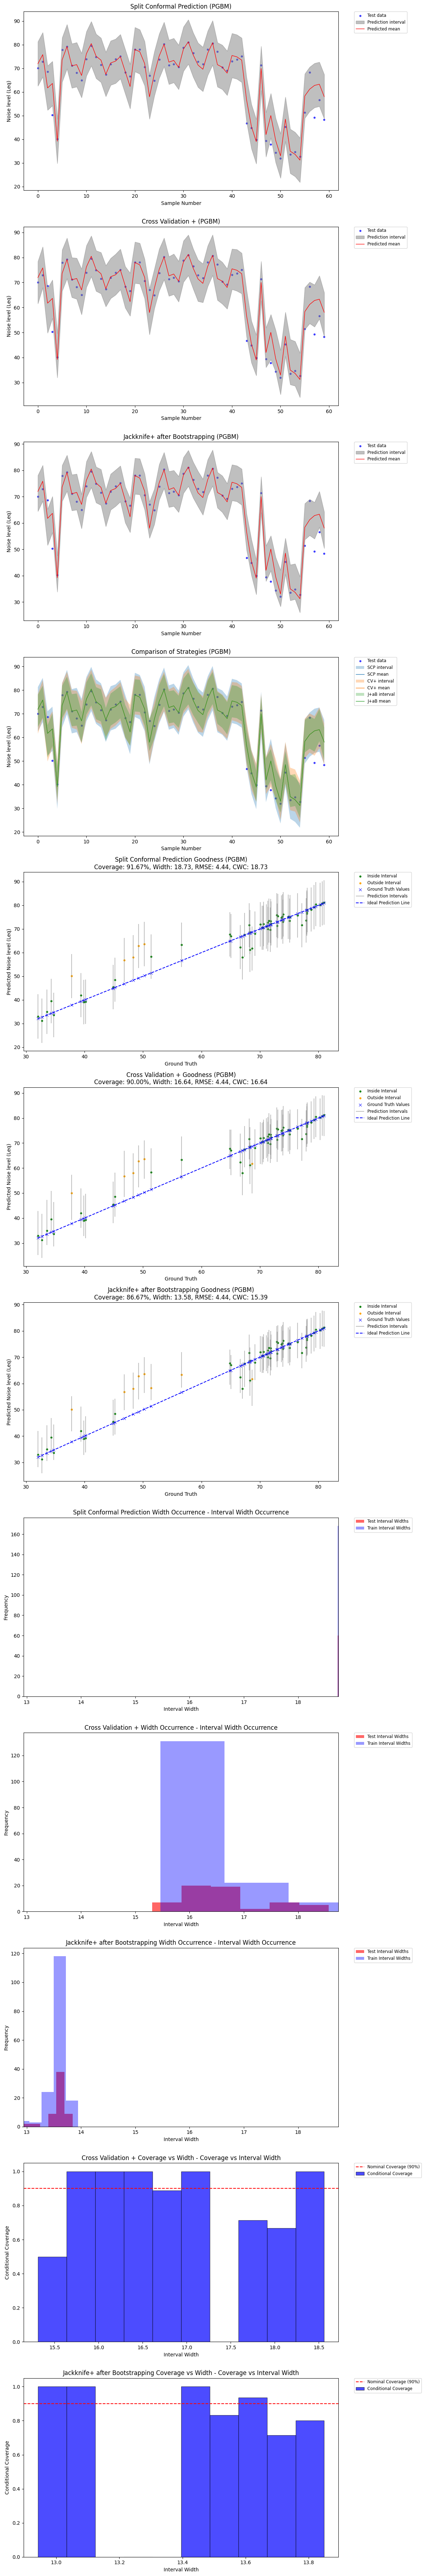

In [48]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax



def conformal_predictions_MAPIE_PGBM(
    model_class,
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name,
    excel_file_path
):
    SEED = 123
    np.random.seed(SEED)
    MISCOVERAGE = ALPHA  # FIX M4: was 0.05
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)

    # Convert y_test to a NumPy array if it has to_numpy
    y_test_np = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test

    # Map method names to descriptive labels
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }

    # Corresponding parameters for each strategy
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Create a base estimator object for each strategy
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    # Fit & predict using MapieRegressor for each strategy
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)


    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred)
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the intervals and predictions for each strategy
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names)*3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(12, 6 * n_figs))
    plot_index = 0

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                            color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red',
                                    label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Comparison subplot (moved after individual strategy plots)
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                        alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name],
                                label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1


    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1


    fig.tight_layout()

    # Save plots to Excel
    # Save plots to Excel
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        sheet_name = 'conformal_predictions_MAPIE'
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        #NEW: Save all predictions/intervals to one worksheet
        all_rows = []
        # Always use y_test_np for consistent array-ness
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = ((y_test_np >= ymin_np) & (y_test_np <= ymax_np)).astype(int)
            residual_np = y_test_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_test_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np,
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet2 = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet2.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet2.cell(row=i+2, column=j, value=float(value) if isinstance(value, np.generic) else value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))



# Example call (assuming best_params, X_train, y_train, X_test, y_test are defined elsewhere)
conformal_predictions_MAPIE_PGBM(
    model_class=PGBMWrapper,
    best_params=best_params,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="PGBM",
    excel_file_path="./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx"
)

In [49]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC_PGBM(
    X_train,
    y_train,
    X_test,
    y_test,
    best_scores_autosampler,
    model_class,
    excel_file_path=None,
    model_params=None,
    alpha=ALPHA  # FIX M4: was 0.1
):
    if model_params is None:
        if model_class.__name__ == 'PGBMWrapper':
            model_params = get_best_model_params(best_scores_autosampler, 'PGBM')
        else:
            model_params = {}

    # Initialize model
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    # Convert to NumPy arrays if needed
    y_train_np = y_train.to_numpy() if isinstance(y_train, pd.Series) else y_train
    model.fit(X_train, y_train_np)

    y_test_np = y_test.to_numpy() if isinstance(y_test, pd.Series) else y_test

    def evaluate_cp(X_test_eval, y_test_eval, model_cp, alpha_val):
        X_test_np = X_test_eval.to_numpy() if isinstance(X_test_eval, pd.DataFrame) else np.array(X_test_eval)
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test_np, alpha=alpha_val)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test_eval, y_pred_lower, y_pred_upper)
        return y_pred, y_pred_lower, y_pred_upper, sharpness, coverage

    # Base predictor setup
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train_np, fit_ratio=0.5)

    y_pred_sc, y_lower_sc, y_upper_sc, sharpness_sc, coverage_sc = evaluate_cp(X_test, y_test_np, splitcp, alpha)

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train_np)
    y_pred, y_lower_cv, y_upper_cv, sharpness_cv, coverage_cv = evaluate_cp(X_test, y_test_np, cvplus, alpha)

    # CQR
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train_np, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_lower_cqr, y_upper_cqr, sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test_np, cqr, alpha)
    y_pred_cqr = 0.5 * (y_lower_cqr + y_upper_cqr)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness_sc:.3f}")
    print(f"SplitCP - Average coverage: {coverage_sc*100:.3f}%")
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cv:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cv*100:.3f}%")
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")


    # Plotting
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    sample_indices = np.arange(len(y_test_np))

    # Plot results for each method
    for idx, (y_pred, y_lower, y_upper, title) in enumerate([
        (y_pred_sc, y_lower_sc, y_upper_sc, 'SplitCP'),
        (y_pred_sc, y_lower_cv, y_upper_cv, 'CVPlus'),
        (y_pred_cqr, y_lower_cqr, y_upper_cqr, 'CQR')
    ]):
        axs[idx].scatter(sample_indices, y_test_np, label='True', color='blue', s=10, alpha=0.7)
        axs[idx].fill_between(sample_indices, y_lower, y_upper, color='gray', alpha=0.5, label='Prediction interval')
        axs[idx].plot(sample_indices, y_pred, color='red', label='Predicted mean', linewidth=1)
        axs[idx].set_title(f'{title}: Prediction Intervals with Conformal Prediction')
        axs[idx].set_xlabel('Sample Number')
        axs[idx].set_ylabel(f'{TARGET_LABEL}')
        axs[idx].legend(fontsize='small')

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_sc).reshape(-1),
        'SplitCP_lower': np.asarray(y_lower_sc).reshape(-1),
        'SplitCP_upper': np.asarray(y_upper_sc).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_sc).reshape(-1),
        'CVPlus_lower': np.asarray(y_lower_cv).reshape(-1),
        'CVPlus_upper': np.asarray(y_upper_cv).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

# Example usage (assuming X_train, y_train, X_test, y_test, best_scores_autosampler exist):
conformal_predictions_PUNCC_PGBM(
    X_train, y_train,
    X_test, y_test,
    best_scores_autosampler=best_scores_autosampler,
    model_class=PGBMWrapper,
    excel_file_path="./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx",
    alpha=0.1
)


Training on CPU
Estimator 0/100, Train metric: 13.5823
Estimator 1/100, Train metric: 12.9859
Estimator 2/100, Train metric: 12.4356
Estimator 3/100, Train metric: 11.9029
Estimator 4/100, Train metric: 11.4019
Estimator 5/100, Train metric: 10.9165
Estimator 6/100, Train metric: 10.4506
Estimator 7/100, Train metric: 10.0087
Estimator 8/100, Train metric: 9.5896
Estimator 9/100, Train metric: 9.1922
Estimator 10/100, Train metric: 8.8209
Estimator 11/100, Train metric: 8.4728
Estimator 12/100, Train metric: 8.1313
Estimator 13/100, Train metric: 7.8142
Estimator 14/100, Train metric: 7.5028
Estimator 15/100, Train metric: 7.2011
Estimator 16/100, Train metric: 6.9205
Estimator 17/100, Train metric: 6.6474
Estimator 18/100, Train metric: 6.3886
Estimator 19/100, Train metric: 6.1544


Estimator 20/100, Train metric: 5.9238
Estimator 21/100, Train metric: 5.7004
Estimator 22/100, Train metric: 5.5008
Estimator 23/100, Train metric: 5.2968
Estimator 24/100, Train metric: 5.1073
Estimator 25/100, Train metric: 4.9373
Estimator 26/100, Train metric: 4.7665
Estimator 27/100, Train metric: 4.6124
Estimator 28/100, Train metric: 4.4596
Estimator 29/100, Train metric: 4.3087
Estimator 30/100, Train metric: 4.1734
Estimator 31/100, Train metric: 4.0334
Estimator 32/100, Train metric: 3.9122
Estimator 33/100, Train metric: 3.7774
Estimator 34/100, Train metric: 3.6682
Estimator 35/100, Train metric: 3.5549
Estimator 36/100, Train metric: 3.4547
Estimator 37/100, Train metric: 3.3491


Estimator 38/100, Train metric: 3.2461
Estimator 39/100, Train metric: 3.1490
Estimator 40/100, Train metric: 3.0611
Estimator 41/100, Train metric: 2.9699
Estimator 42/100, Train metric: 2.8949
Estimator 43/100, Train metric: 2.8201
Estimator 44/100, Train metric: 2.7370
Estimator 45/100, Train metric: 2.6646
Estimator 46/100, Train metric: 2.6019
Estimator 47/100, Train metric: 2.5310
Estimator 48/100, Train metric: 2.4609
Estimator 49/100, Train metric: 2.3927
Estimator 50/100, Train metric: 2.3280


Estimator 51/100, Train metric: 2.2702
Estimator 52/100, Train metric: 2.2238
Estimator 53/100, Train metric: 2.1783
Estimator 54/100, Train metric: 2.1239
Estimator 55/100, Train metric: 2.0783
Estimator 56/100, Train metric: 2.0355
Estimator 57/100, Train metric: 1.9918
Estimator 58/100, Train metric: 1.9570
Estimator 59/100, Train metric: 1.9246
Estimator 60/100, Train metric: 1.8874
Estimator 61/100, Train metric: 1.8525


Estimator 62/100, Train metric: 1.8198
Estimator 63/100, Train metric: 1.7931
Estimator 64/100, Train metric: 1.7600
Estimator 65/100, Train metric: 1.7228
Estimator 66/100, Train metric: 1.6955
Estimator 67/100, Train metric: 1.6707
Estimator 68/100, Train metric: 1.6382
Estimator 69/100, Train metric: 1.6160
Estimator 70/100, Train metric: 1.5903
Estimator 71/100, Train metric: 1.5584


Estimator 72/100, Train metric: 1.5285
Estimator 73/100, Train metric: 1.5093
Estimator 74/100, Train metric: 1.4875
Estimator 75/100, Train metric: 1.4608
Estimator 76/100, Train metric: 1.4425
Estimator 77/100, Train metric: 1.4257
Estimator 78/100, Train metric: 1.4030
Estimator 79/100, Train metric: 1.3868
Estimator 80/100, Train metric: 1.3716
Estimator 81/100, Train metric: 1.3514


... (47 outputs left out)

Estimator 51/100, Train metric: 2.5584
Estimator 52/100, Train metric: 2.4980
Estimator 53/100, Train metric: 2.4408
Estimator 54/100, Train metric: 2.3763
Estimator 55/100, Train metric: 2.3262
Estimator 56/100, Train metric: 2.2716
Estimator 57/100, Train metric: 2.2366
Estimator 58/100, Train metric: 2.1868
Estimator 59/100, Train metric: 2.1425
Estimator 60/100, Train metric: 2.0918
Estimator 61/100, Train metric: 2.0621
Estimator 62/100, Train metric: 2.0215
Estimator 63/100, Train metric: 1.9764
Estimator 64/100, Train metric: 1.9367
Estimator 65/100, Train metric: 1.9007
Estimator 66/100, Train metric: 1.8659
Estimator 67/100, Train metric: 1.8365
Estimator 68/100, Train metric: 1.8001
Estimator 69/100, Train metric: 1.7660
Estimator 70/100, Train metric: 1.7392


Estimator 71/100, Train metric: 1.7165
Estimator 72/100, Train metric: 1.6855
Estimator 73/100, Train metric: 1.6655
Estimator 74/100, Train metric: 1.6366
Estimator 75/100, Train metric: 1.6120
Estimator 76/100, Train metric: 1.5888
Estimator 77/100, Train metric: 1.5716
Estimator 78/100, Train metric: 1.5484
Estimator 79/100, Train metric: 1.5247
Estimator 80/100, Train metric: 1.5092
Estimator 81/100, Train metric: 1.4789
Estimator 82/100, Train metric: 1.4583
Estimator 83/100, Train metric: 1.4389
Estimator 84/100, Train metric: 1.4150
Estimator 85/100, Train metric: 1.3926
Estimator 86/100, Train metric: 1.3734
Estimator 87/100, Train metric: 1.3558
Estimator 88/100, Train metric: 1.3260
Estimator 89/100, Train metric: 1.3073


Estimator 90/100, Train metric: 1.2912
Estimator 91/100, Train metric: 1.2760
Estimator 92/100, Train metric: 1.2593
Estimator 93/100, Train metric: 1.2488
Estimator 94/100, Train metric: 1.2351
Estimator 95/100, Train metric: 1.2255
Estimator 96/100, Train metric: 1.2125
Estimator 97/100, Train metric: 1.1954
Estimator 98/100, Train metric: 1.1794
Estimator 99/100, Train metric: 1.1661


SplitCP - Average prediction intervals width (sharpness): 21.186
SplitCP - Average coverage: 95.000%
CVPlus - Average prediction intervals width (sharpness): 15.313
CVPlus - Average coverage: 91.667%
CQR - Average prediction intervals width (sharpness): 13.997
CQR - Average coverage: 86.667%


In [50]:
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, PGBMWrapper, best_params,"./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx", "PGBM Prediction Intervals")

Training on CPU
Estimator 0/100, Train metric: 13.5823
Estimator 1/100, Train metric: 12.9859
Estimator 2/100, Train metric: 12.4356
Estimator 3/100, Train metric: 11.9029
Estimator 4/100, Train metric: 11.4019
Estimator 5/100, Train metric: 10.9165
Estimator 6/100, Train metric: 10.4506
Estimator 7/100, Train metric: 10.0087
Estimator 8/100, Train metric: 9.5896
Estimator 9/100, Train metric: 9.1922
Estimator 10/100, Train metric: 8.8209
Estimator 11/100, Train metric: 8.4728
Estimator 12/100, Train metric: 8.1313
Estimator 13/100, Train metric: 7.8142
Estimator 14/100, Train metric: 7.5028
Estimator 15/100, Train metric: 7.2011
Estimator 16/100, Train metric: 6.9205
Estimator 17/100, Train metric: 6.6474
Estimator 18/100, Train metric: 6.3886
Estimator 19/100, Train metric: 6.1544


Estimator 20/100, Train metric: 5.9238
Estimator 21/100, Train metric: 5.7004
Estimator 22/100, Train metric: 5.5008
Estimator 23/100, Train metric: 5.2968
Estimator 24/100, Train metric: 5.1073
Estimator 25/100, Train metric: 4.9373
Estimator 26/100, Train metric: 4.7665
Estimator 27/100, Train metric: 4.6124
Estimator 28/100, Train metric: 4.4596
Estimator 29/100, Train metric: 4.3087
Estimator 30/100, Train metric: 4.1734
Estimator 31/100, Train metric: 4.0334
Estimator 32/100, Train metric: 3.9122
Estimator 33/100, Train metric: 3.7774
Estimator 34/100, Train metric: 3.6682
Estimator 35/100, Train metric: 3.5549
Estimator 36/100, Train metric: 3.4547


Estimator 37/100, Train metric: 3.3491
Estimator 38/100, Train metric: 3.2461
Estimator 39/100, Train metric: 3.1490
Estimator 40/100, Train metric: 3.0611
Estimator 41/100, Train metric: 2.9699
Estimator 42/100, Train metric: 2.8949
Estimator 43/100, Train metric: 2.8201
Estimator 44/100, Train metric: 2.7370
Estimator 45/100, Train metric: 2.6646
Estimator 46/100, Train metric: 2.6019
Estimator 47/100, Train metric: 2.5310
Estimator 48/100, Train metric: 2.4609
Estimator 49/100, Train metric: 2.3927


Estimator 50/100, Train metric: 2.3280
Estimator 51/100, Train metric: 2.2702
Estimator 52/100, Train metric: 2.2238
Estimator 53/100, Train metric: 2.1783
Estimator 54/100, Train metric: 2.1239
Estimator 55/100, Train metric: 2.0783
Estimator 56/100, Train metric: 2.0355
Estimator 57/100, Train metric: 1.9918
Estimator 58/100, Train metric: 1.9570
Estimator 59/100, Train metric: 1.9246
Estimator 60/100, Train metric: 1.8874


Estimator 61/100, Train metric: 1.8525
Estimator 62/100, Train metric: 1.8198
Estimator 63/100, Train metric: 1.7931
Estimator 64/100, Train metric: 1.7600
Estimator 65/100, Train metric: 1.7228
Estimator 66/100, Train metric: 1.6955
Estimator 67/100, Train metric: 1.6707
Estimator 68/100, Train metric: 1.6382
Estimator 69/100, Train metric: 1.6160
Estimator 70/100, Train metric: 1.5903


Estimator 71/100, Train metric: 1.5584
Estimator 72/100, Train metric: 1.5285
Estimator 73/100, Train metric: 1.5093
Estimator 74/100, Train metric: 1.4875
Estimator 75/100, Train metric: 1.4608
Estimator 76/100, Train metric: 1.4425
Estimator 77/100, Train metric: 1.4257
Estimator 78/100, Train metric: 1.4030
Estimator 79/100, Train metric: 1.3868


... (324 outputs left out)

Estimator 64/100, Train metric: 1.3249
Estimator 65/100, Train metric: 1.2917
Estimator 66/100, Train metric: 1.2639
Estimator 67/100, Train metric: 1.2363
Estimator 68/100, Train metric: 1.2060
Estimator 69/100, Train metric: 1.1894
Estimator 70/100, Train metric: 1.1626
Estimator 71/100, Train metric: 1.1357
Estimator 72/100, Train metric: 1.1104
Estimator 73/100, Train metric: 1.0898
Estimator 74/100, Train metric: 1.0673


Estimator 75/100, Train metric: 1.0434
Estimator 76/100, Train metric: 1.0234
Estimator 77/100, Train metric: 1.0118
Estimator 78/100, Train metric: 0.9888
Estimator 79/100, Train metric: 0.9708
Estimator 80/100, Train metric: 0.9540
Estimator 81/100, Train metric: 0.9347
Estimator 82/100, Train metric: 0.9150
Estimator 83/100, Train metric: 0.9000
Estimator 84/100, Train metric: 0.8829
Estimator 85/100, Train metric: 0.8692


Estimator 86/100, Train metric: 0.8534
Estimator 87/100, Train metric: 0.8386
Estimator 88/100, Train metric: 0.8309
Estimator 89/100, Train metric: 0.8158
Estimator 90/100, Train metric: 0.8045
Estimator 91/100, Train metric: 0.7901
Estimator 92/100, Train metric: 0.7792
Estimator 93/100, Train metric: 0.7641
Estimator 94/100, Train metric: 0.7512
Estimator 95/100, Train metric: 0.7400
Estimator 96/100, Train metric: 0.7296


Estimator 97/100, Train metric: 0.7240
Estimator 98/100, Train metric: 0.7067
Estimator 99/100, Train metric: 0.6965


# **Conformal Predictions with TabNet**

In [51]:
best_params = get_best_model_params(best_scores_autosampler, 'TabNet')
print(best_params)

{'n_d': 16, 'n_a': 16, 'n_steps': 10, 'gamma': 2.0, 'lambda_sparse': 0.01, 'optimizer_params': {'lr': 0.02}, 'mask_type': 'entmax', 'n_shared': 1, 'n_independent': 1, 'scheduler_params': {'step_size': 10, 'gamma': 0.9}, 'scheduler_fn': <class 'torch.optim.lr_scheduler.StepLR'>, 'seed': 42, 'verbose': 0}


In [52]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class TabNetRegressorCP(TabNetRegressor):
    def fit(self, X, y, *args, **kwargs):
        y_ = np.array(y)
        if y_.ndim == 1:
            y_ = y_.reshape(-1, 1)
        return super().fit(X, y_, *args, **kwargs)
    def predict(self, X, *args, **kwargs):
        preds = super().predict(X, *args, **kwargs)
        return preds.flatten()
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.mean((y_arr >= int_pred[strat_name][:, 0]) & (y_arr <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.sqrt(mean_squared_error(y_arr, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        y_arr = np.array(y_test)
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_arr[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) &
                                           (y_arr[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan)
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages
class visualize:
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        y_true_np = np.array(y_true).ravel()
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')
        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)],
                 linestyle='--', color='blue', label='Ideal Prediction Line')
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')
        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()
        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]
        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE_tabnet(
    model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path
):
    is_tabnet = ("TabNet" in model_name or "TabNet" in model_class.__name__)

    # Remove 'verbose' if present to avoid TypeError in TabNet
    if isinstance(best_params, dict) and "verbose" in best_params:
        best_params = dict(best_params) # make a copy!
        best_params.pop("verbose", None)

    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    MISCOVERAGE = ALPHA  # FIX M4
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 5},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {}

    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(np.array(X_train), np.array(y_train))
        y_pred_raw, int_pred_raw = mapie.predict(np.array(X_test), alpha=MISCOVERAGE)
        y_pred[strat_name] = y_pred_raw.flatten()
        int_pred[strat_name] = np.array(int_pred_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train_raw, int_pred_train_raw = mapie.predict(np.array(X_train), alpha=MISCOVERAGE)
        y_pred_train[strat_name] = y_pred_train_raw.flatten()
        int_pred_train[strat_name] = np.array(int_pred_train_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # All metric calls now use np.array(y_test)
    coverages = validate.coverage(int_pred, np.array(y_test))
    widths = validate.width(int_pred)
    rmse_vals = validate.rmse(y_pred, np.array(y_test))
    cwc_vals = validate.cwc(int_pred, np.array(y_test), MISCOVERAGE)

    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            rmse = rmse_vals[strat_name]
            interval_width = widths[strat_name]
            coverage = coverages[strat_name]
            cwc = cwc_vals[strat_name]
            ssc = np.mean((np.array(y_test) - y_pred[strat_name])**2 +
                          (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)
            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}\n")

    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS = N_BINS  # FIX D4
    n_figs = len(strategies_names) * 3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))
    plot_index = 0

    # Individual strategy plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)
    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()
            axs[plot_index] = visualize.goodness(
                np.array(y_test), y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})',
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages = validate.cond_coverage(int_pred, np.array(y_test), num_bins=NUM_BINS)
    for _strat in _strategies:
        axs[plot_index] = visualize.coverage_by_width(
            np.array(y_test), int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = f'conformal_predictions_MAPIE_{model_name}'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        # Tabular export
        all_rows = []
        y_true_np = np.array(y_test).ravel()
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np
            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)
        all_pred_sheet_name = 'all_pred_values_' + model_name
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1
        worksheet = workbook.create_sheet(title=all_pred_sheet_name)
        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()


conformal_predictions_MAPIE_tabnet(
    TabNetRegressorCP,        # <------ use the wrapper here!
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    "TabNet",
    "./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx"
)

epoch 0  | loss: 4406.87109|  0:00:00s
epoch 1  | loss: 4168.32373|  0:00:00s
epoch 2  | loss: 3943.06274|  0:00:00s
epoch 3  | loss: 3706.19165|  0:00:00s
epoch 4  | loss: 3481.24268|  0:00:00s
epoch 5  | loss: 3258.33838|  0:00:00s
epoch 6  | loss: 3049.59741|  0:00:00s
epoch 7  | loss: 2846.03052|  0:00:00s


epoch 8  | loss: 2646.80981|  0:00:00s
epoch 9  | loss: 2444.34741|  0:00:00s
epoch 10 | loss: 2228.81494|  0:00:00s
epoch 11 | loss: 2012.60608|  0:00:00s
epoch 12 | loss: 1789.61853|  0:00:00s
epoch 13 | loss: 1616.29138|  0:00:00s
epoch 14 | loss: 1436.24951|  0:00:00s
epoch 15 | loss: 1248.02393|  0:00:00s


epoch 16 | loss: 1073.25903|  0:00:00s
epoch 17 | loss: 889.367 |  0:00:00s
epoch 18 | loss: 717.97357|  0:00:00s
epoch 19 | loss: 558.78632|  0:00:00s
epoch 20 | loss: 428.36334|  0:00:00s
epoch 21 | loss: 323.34323|  0:00:00s
epoch 22 | loss: 227.41643|  0:00:00s
epoch 23 | loss: 158.46631|  0:00:00s


epoch 24 | loss: 115.26753|  0:00:00s
epoch 25 | loss: 102.25087|  0:00:00s
epoch 26 | loss: 108.65781|  0:00:00s
epoch 27 | loss: 113.44463|  0:00:00s
epoch 28 | loss: 110.99117|  0:00:00s
epoch 29 | loss: 102.23242|  0:00:00s
epoch 30 | loss: 90.41089|  0:00:00s
epoch 31 | loss: 72.66817|  0:00:00s


epoch 32 | loss: 69.46304|  0:00:01s
epoch 33 | loss: 56.92118|  0:00:01s
epoch 34 | loss: 50.86752|  0:00:01s
epoch 35 | loss: 46.0803 |  0:00:01s
epoch 36 | loss: 49.1548 |  0:00:01s
epoch 37 | loss: 46.61367|  0:00:01s
epoch 38 | loss: 39.91665|  0:00:01s
epoch 39 | loss: 36.18806|  0:00:01s


epoch 40 | loss: 31.27368|  0:00:01s
epoch 41 | loss: 30.73919|  0:00:01s
epoch 42 | loss: 34.21833|  0:00:01s
epoch 43 | loss: 36.93421|  0:00:01s
epoch 44 | loss: 35.85506|  0:00:01s
epoch 45 | loss: 33.86917|  0:00:01s
epoch 46 | loss: 42.95405|  0:00:01s
epoch 47 | loss: 56.13475|  0:00:01s


... (760 outputs left out)

epoch 81 | loss: 12.41032|  0:00:02s
epoch 82 | loss: 11.21235|  0:00:02s
epoch 83 | loss: 10.42167|  0:00:02s
epoch 84 | loss: 10.29794|  0:00:02s
epoch 85 | loss: 11.01017|  0:00:02s
epoch 86 | loss: 9.57946 |  0:00:02s
epoch 87 | loss: 9.79317 |  0:00:02s
epoch 88 | loss: 9.87905 |  0:00:02s


epoch 89 | loss: 8.62696 |  0:00:02s
epoch 90 | loss: 10.57112|  0:00:02s
epoch 91 | loss: 11.61046|  0:00:02s
epoch 92 | loss: 15.1665 |  0:00:02s
epoch 93 | loss: 9.82511 |  0:00:02s
epoch 94 | loss: 8.91928 |  0:00:02s
epoch 95 | loss: 8.79279 |  0:00:02s
epoch 96 | loss: 9.38242 |  0:00:02s


epoch 97 | loss: 8.63878 |  0:00:02s
epoch 98 | loss: 8.74712 |  0:00:02s
epoch 99 | loss: 10.93744|  0:00:02s


Strategy: Split Conformal Prediction
  RMSE: 9.3876
  Interval Width: 21.0173
  Coverage: 81.67%
  CWC: 24.8705
  SSC: 529.8542

Strategy: Cross Validation +
  RMSE: 9.3876
  Interval Width: 36.9449
  Coverage: 95.00%
  CWC: 36.9449
  SSC: 1485.5056

Strategy: Jackknife+ after Bootstrapping
  RMSE: 9.3876
  Interval Width: 27.0717
  Coverage: 88.33%
  CWC: 30.2301
  SSC: 821.1374



In [53]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

def conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Get best parameters if not supplied
    if model_params is None:
        model_params = get_best_model_params(best_scores_autosampler, 'TabNet')
        if "verbose" in model_params:
            model_params = dict(model_params)
            model_params.pop("verbose", None)

    model_class = TabNetRegressorCP

    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing TabNet: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_te, y_te, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_te, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(np.array(y_te), y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Base predictor
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    picp_splitcp = np.mean((np.array(y_test).ravel() >= y_pred_lower_splitcp) &
                           (np.array(y_test).ravel() <= y_pred_upper_splitcp))
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")
    print(f"SplitCP - PICP: {picp_splitcp*100:.3f}%")

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness_cvplus, coverage_cvplus = evaluate_cp(X_test, y_test, cvplus, alpha)
    picp_cvplus = np.mean((np.array(y_test).ravel() >= y_pred_lower_cvplus) &
                          (np.array(y_test).ravel() <= y_pred_upper_cvplus))
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cvplus:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cvplus*100:.3f}%")
    print(f"CVPlus - PICP: {picp_cvplus*100:.3f}%\n")

    # CQR
    from sklearn.model_selection import train_test_split
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test, cqr, alpha)
    picp_cqr = np.mean((np.array(y_test).ravel() >= y_pred_lower_cqr) &
                       (np.array(y_test).ravel() <= y_pred_upper_cqr))
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")
    print(f"CQR - PICP: {picp_cqr*100:.3f}%\n")

    # Plot
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    arr_y_test = np.array(y_test).ravel()
    axs[0].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(arr_y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[1].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[2].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(arr_y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export ---
    results_dict = {
        'SplitCP_true': arr_y_test.reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': arr_y_test.reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': arr_y_test.reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC_TabNet')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_TabNet_values')

    plt.close(fig)


conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path="./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    model_params=best_params  # your best params for TabNet
)

SplitCP - Average prediction intervals width (sharpness): 48.397
SplitCP - Average coverage: 91.667%
SplitCP - PICP: 91.667%


CVPlus - Average prediction intervals width (sharpness): 37.240
CVPlus - Average coverage: 93.333%
CVPlus - PICP: 93.333%



CQR - Average prediction intervals width (sharpness): 27.210
CQR - Average coverage: 83.333%
CQR - PICP: 83.333%



In [54]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params,
    excel_file_path=None,
    suptitle: str = "TabNet Prediction Intervals"
) -> None:
    # Use wrapper for TabNet
    model_cls = TabNetRegressorCP

    # Train model with MAPIE
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [np.array(y_train).min(), np.array(y_train).max()],
            [np.array(y_train).min(), np.array(y_train).max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        np.array(y_train).ravel(),
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        np.array(y_test).ravel(),
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        # Use a fresh model each time (sklearn style)
        mapie = MapieRegressor(model_cls(**model_params), **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_2')

    plt.close(fig)

# Helper method for Excel plotting export
def save_plot_to_excel(fig, excel_file_path, sheet_name):
    import io
    from openpyxl import load_workbook
    from openpyxl.drawing.image import Image
    from PIL import Image as PILImage
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PILImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)
        worksheet.add_image(img, 'A1')
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))


prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params=best_params,
    excel_file_path="./drive/MyDrive/Regression/noise_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    suptitle="TabNet Prediction Intervals"
)